In [12]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from logisticRegrassionPipeline import LogisticRegScratch

Training: lr=0.001, epochs=500
Training: lr=0.001, epochs=1000
Training: lr=0.001, epochs=2500
Training: lr=0.001, epochs=4000
Training: lr=0.001, epochs=4500
Training: lr=0.001, epochs=5000
Training: lr=0.001, epochs=3500
Training: lr=0.01, epochs=500
Training: lr=0.01, epochs=1000
Training: lr=0.01, epochs=2500
Training: lr=0.01, epochs=4000
Training: lr=0.01, epochs=4500
Training: lr=0.01, epochs=5000
Training: lr=0.01, epochs=3500
Training: lr=0.05, epochs=500
Training: lr=0.05, epochs=1000
Training: lr=0.05, epochs=2500
Training: lr=0.05, epochs=4000
Training: lr=0.05, epochs=4500
Training: lr=0.05, epochs=5000
Training: lr=0.05, epochs=3500
Training: lr=0.1, epochs=500
Training: lr=0.1, epochs=1000
Training: lr=0.1, epochs=2500
Training: lr=0.1, epochs=4000
Training: lr=0.1, epochs=4500
Training: lr=0.1, epochs=5000
Training: lr=0.1, epochs=3500
Training: lr=0.18, epochs=500
Training: lr=0.18, epochs=1000
Training: lr=0.18, epochs=2500
Training: lr=0.18, epochs=4000
Training: lr=

C:\Users\HP\AppData\Local\Temp\ipykernel_27364\1488938751.py:236: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


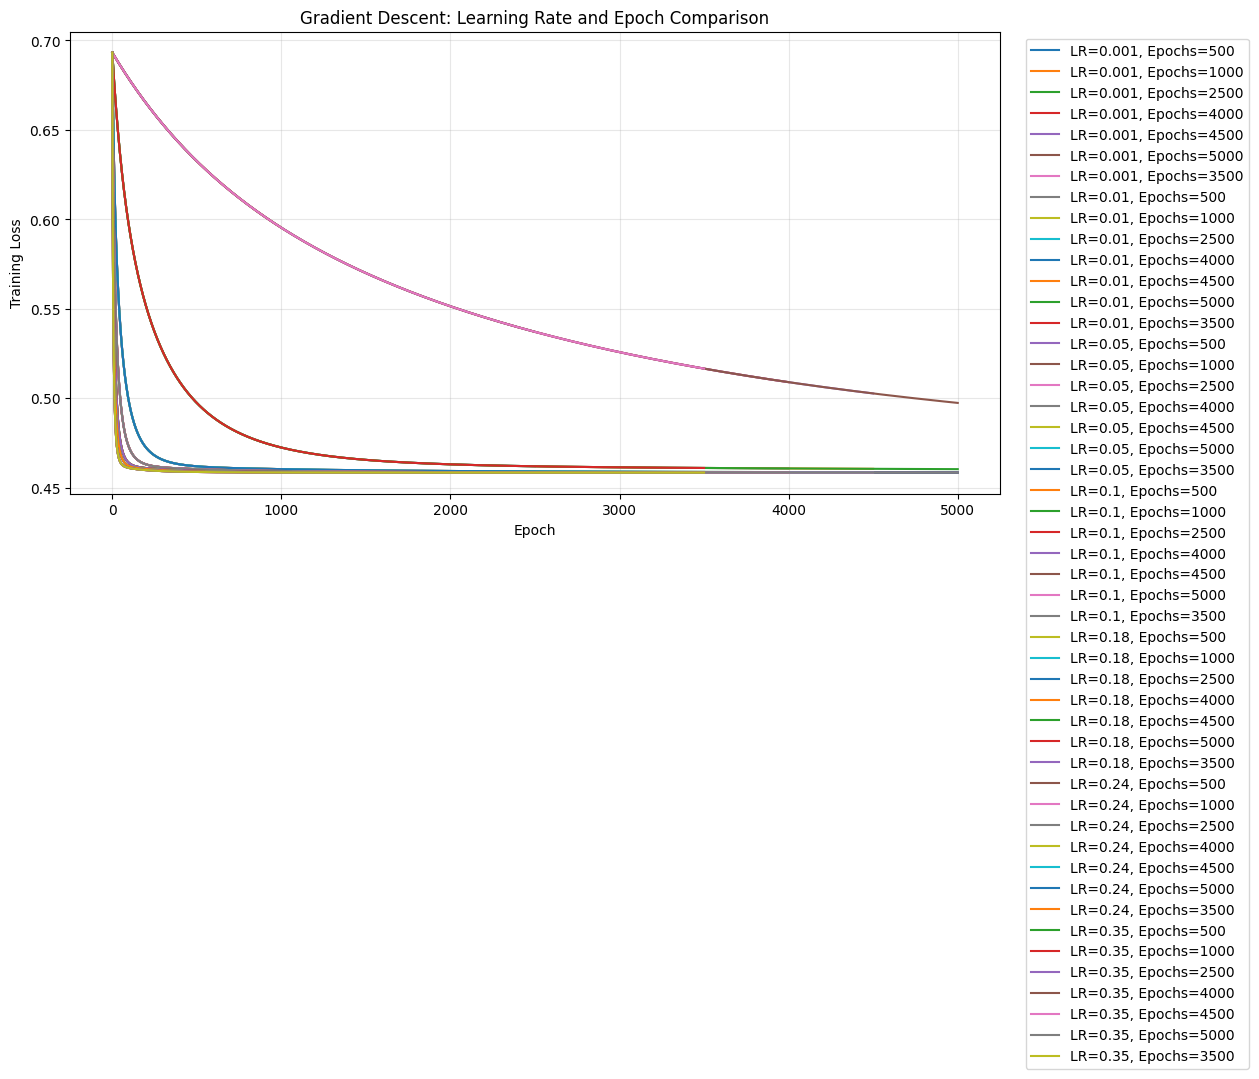

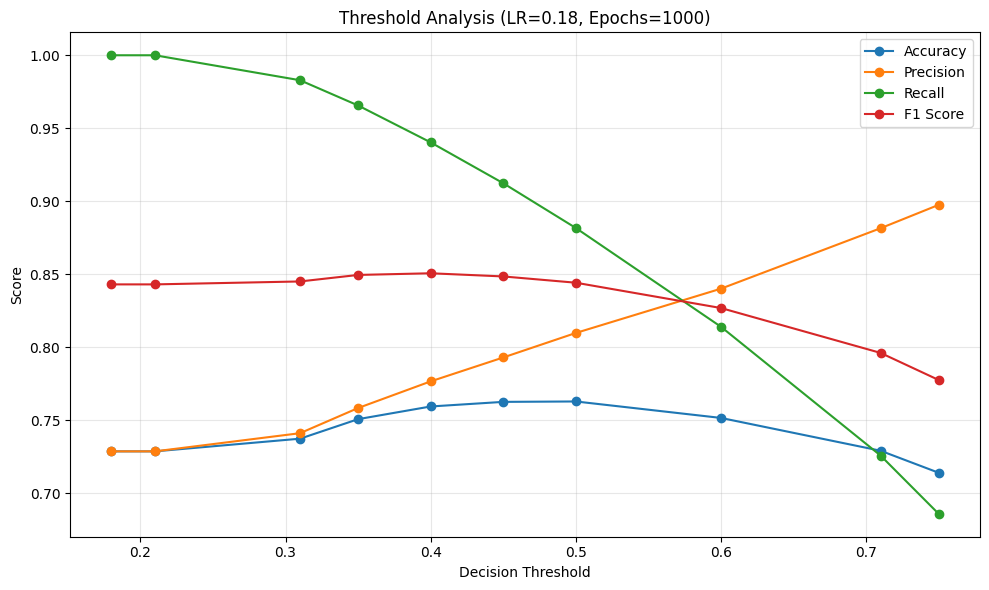


BEST CONFIGURATION
Learning Rate       0.180000
Epochs           1000.000000
Threshold           0.400000
Accuracy            0.759454
Precision           0.776649
Recall              0.940323
F1 Score            0.850685
TN               1060.000000
FP               2814.000000
FN                621.000000
TP               9785.000000
Final Loss          0.458776

Best Validation Confusion Matrix:
[[1060 2814]
 [ 621 9785]]


In [19]:
# 1. Load dataset
data = pd.read_csv("Dataset/retail_store_inventory.csv")
ata = pd.read_csv(
    r"C:\Users\HP\OneDrive\Desktop\New folder\Dataset\retail_store_inventory.csv"
)

data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values(["Store ID", "Product ID", "Date"]).copy()


# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================

group_cols = ["Store ID", "Product ID"]

# Previous 7 days of sales
data["rolling_7d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(1).rolling(7).sum())
)

# Previous 14 days of sales
data["rolling_14d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(1).rolling(14).sum())
)

# Previous 7-day sales compared with the 7 days before that
data["previous_7d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(8).rolling(7).sum())
)

data["sales_trend"] = (
    data["rolling_7d_sales"] - data["previous_7d_sales"]
)

# Inventory coverage based on recent average daily sales
avg_daily_sales = data["rolling_7d_sales"] / 7

data["inventory_to_demand_ratio"] = (
    data["Inventory Level"] /
    avg_daily_sales.replace(0, np.nan)
)

# Current sales relative to current stock plus orders
denominator = data["Inventory Level"] + data["Units Ordered"]

data["stock_pressure_ratio"] = (
    data["Units Sold"] /
    denominator.replace(0, np.nan)
)


# ==========================================
# 3. CREATE TARGET
# ==========================================

# Assumption: supplier replenishment lead time = 3 days
lead_time = 3

data["lead_time_demand"] = (
    data.groupby(group_cols)["Demand Forecast"]
    .transform(
        lambda s: s.shift(-1)
                   .rolling(lead_time)
                   .sum()
                   .shift(-(lead_time - 1))
    )
)

# 1 = inventory insufficient for forecast demand
# 0 = inventory sufficient for forecast demand
data["stockout_risk"] = (
    data["Inventory Level"] < data["lead_time_demand"]
).astype(int)

# Remove rows without enough future data to construct the target
data = data.dropna(subset=["lead_time_demand"]).copy()


features = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "rolling_7d_sales",
    "rolling_14d_sales",
    "inventory_to_demand_ratio",
    "sales_trend",
    "stock_pressure_ratio",
    "Price",
    "Discount",
    "Competitor Pricing"
]

target = "stockout_risk"

X = data[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(data[target], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Target must contain only binary labels 0 and 1.")

if y.nunique() != 2:
    raise ValueError("Dataset must contain both target classes.")


# 2. Split data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()


# 3. Hyperparameter values to test
learning_rates = [0.001, 0.01, 0.05, 0.1,0.18,0.24,0.35]
epoch_values = [500, 1000, 2500,4000,4500,5000,3500]
threshold_values = [0.31, 0.35, 0.40, 0.45, 0.50, 0.60,0.71,0.75,0.21,0.18]

results = []
loss_curves = {}

# 4. Train and evaluate each configuration
for lr in learning_rates:
    for epochs in epoch_values:

        print(f"Training: lr={lr}, epochs={epochs}")

        model = LogisticRegScratch(
            learn_rate=lr,
            epochs=epochs
        )

        model.fit(X_train_scaled, y_train_np)

        # Save gradient descent history
        loss_curves[(lr, epochs)] = model.loss_history.copy()

        # Calculate probabilities only once per trained model
        probabilities = np.asarray(
            model.predict_proba(X_val_scaled)
        ).ravel()

        # Test multiple decision thresholds
        for threshold in threshold_values:

            predictions = (
                probabilities >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y_val_np,
                predictions,
                labels=[0, 1]
            ).ravel()

            results.append({
                "Learning Rate": lr,
                "Epochs": epochs,
                "Threshold": threshold,
                "Accuracy": accuracy_score(
                    y_val_np, predictions
                ),
                "Precision": precision_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "Recall": recall_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "F1 Score": f1_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "TP": tp,
                "Final Loss": model.loss_history[-1]
            })


# 5. Display the best configurations
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\nTOP 15 CONFIGURATIONS")
print(results_df.head(15).round(4).to_string(index=False))

results_df.to_csv(
    "Dataset/hyperparameter_results.csv",
    index=False
)


# 6. Plot gradient descent loss curves
plt.figure(figsize=(12, 6))

for (lr, epochs), losses in loss_curves.items():
    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"LR={lr}, Epochs={epochs}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Gradient Descent: Learning Rate and Epoch Comparison")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 7. Plot threshold vs performance for the top configuration
best = results_df.iloc[0]

best_lr = best["Learning Rate"]
best_epochs = int(best["Epochs"])

best_group = results_df[
    (results_df["Learning Rate"] == best_lr) &
    (results_df["Epochs"] == best_epochs)
].sort_values("Threshold")

plt.figure(figsize=(10, 6))

for metric in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    plt.plot(
        best_group["Threshold"],
        best_group[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    f"Threshold Analysis (LR={best_lr}, Epochs={best_epochs})"
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 8. Show the best result and its confusion matrix
print("\nBEST CONFIGURATION")
print(best.to_string())

best_model = LogisticRegScratch(
    learn_rate=float(best_lr),
    epochs=best_epochs
)

best_model.fit(X_train_scaled, y_train_np)

best_probabilities = best_model.predict_proba(X_val_scaled)
best_predictions = (
    np.asarray(best_probabilities).ravel()
    >= float(best["Threshold"])
).astype(int)

print("\nBest Validation Confusion Matrix:")
print(confusion_matrix(
    y_val_np,
    best_predictions,
    labels=[0, 1]
))